# 01 – Exploratory analysis of C-MAPSS FD001

**Purpose:** understand the data before modelling, and make evidence-based decisions about
(1) which sensors to keep, (2) how to define the RUL label, and (3) how long engines last.

Cells marked **Your observation** are for you to fill in after looking at the output.
These notes feed directly into the report (feature selection and data-handling justification).

## 1. Setup and loading

In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in notebooks/, so add the repo root to the import path.
REPO_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(REPO_ROOT))

from src.data_loader import (
    SENSOR_COLUMNS, SETTING_COLUMNS, add_rul, load_fd001,
)

train, test, rul_test = load_fd001()
train = add_rul(train)  # uncapped RUL = last cycle - current cycle
print("train:", train.shape, "| test:", test.shape, "| test RUL values:", len(rul_test))
train.head()

train: (20631, 27) | test: (13096, 26) | test RUL values: 100


,engine,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


## 2. How long do engines last?

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


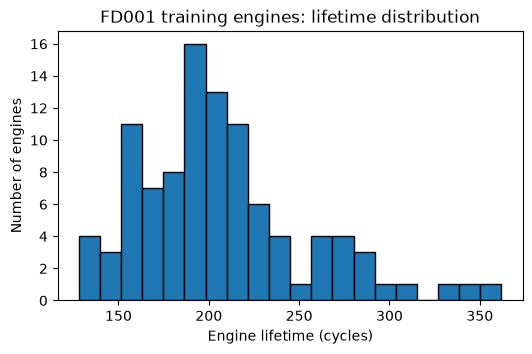

In [9]:
lifetimes = train.groupby("engine")["cycle"].max()
print(lifetimes.describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(lifetimes, bins=20, edgecolor="black")
ax.set_xlabel("Engine lifetime (cycles)")
ax.set_ylabel("Number of engines")
ax.set_title("FD001 training engines: lifetime distribution")
plt.show()

**Your observation:** How much do lifetimes vary between engines? Why does that matter for a model
that predicts RUL from the sensor readings alone?

## 3. Which columns carry no information?

In [10]:
inputs = SETTING_COLUMNS + SENSOR_COLUMNS
n_unique = train[inputs].nunique()
constant = n_unique[n_unique == 1].index.tolist()
near_constant = n_unique[(n_unique > 1) & (n_unique <= 3)].index.tolist()
print("Constant in training data:", constant)
print("Only 2-3 distinct values:", near_constant)
print()
print(train[["setting_1", "setting_2"]].describe().round(5))

Constant in training data: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Only 2-3 distinct values: ['sensor_6']

         setting_1    setting_2
count  20631.00000  20631.00000
mean      -0.00001      0.00000
std        0.00219      0.00029
min       -0.00870     -0.00060
25%       -0.00150     -0.00020
50%        0.00000      0.00000
75%        0.00150      0.00030
max        0.00870      0.00060


**Your observation:** Which columns could you drop, and what is your justification?
Note that "constant in training" is a decision you must make using *training data only*
(why does it matter that you didn't look at the test set to decide this?).

## 4. Do sensors change as engines degrade?

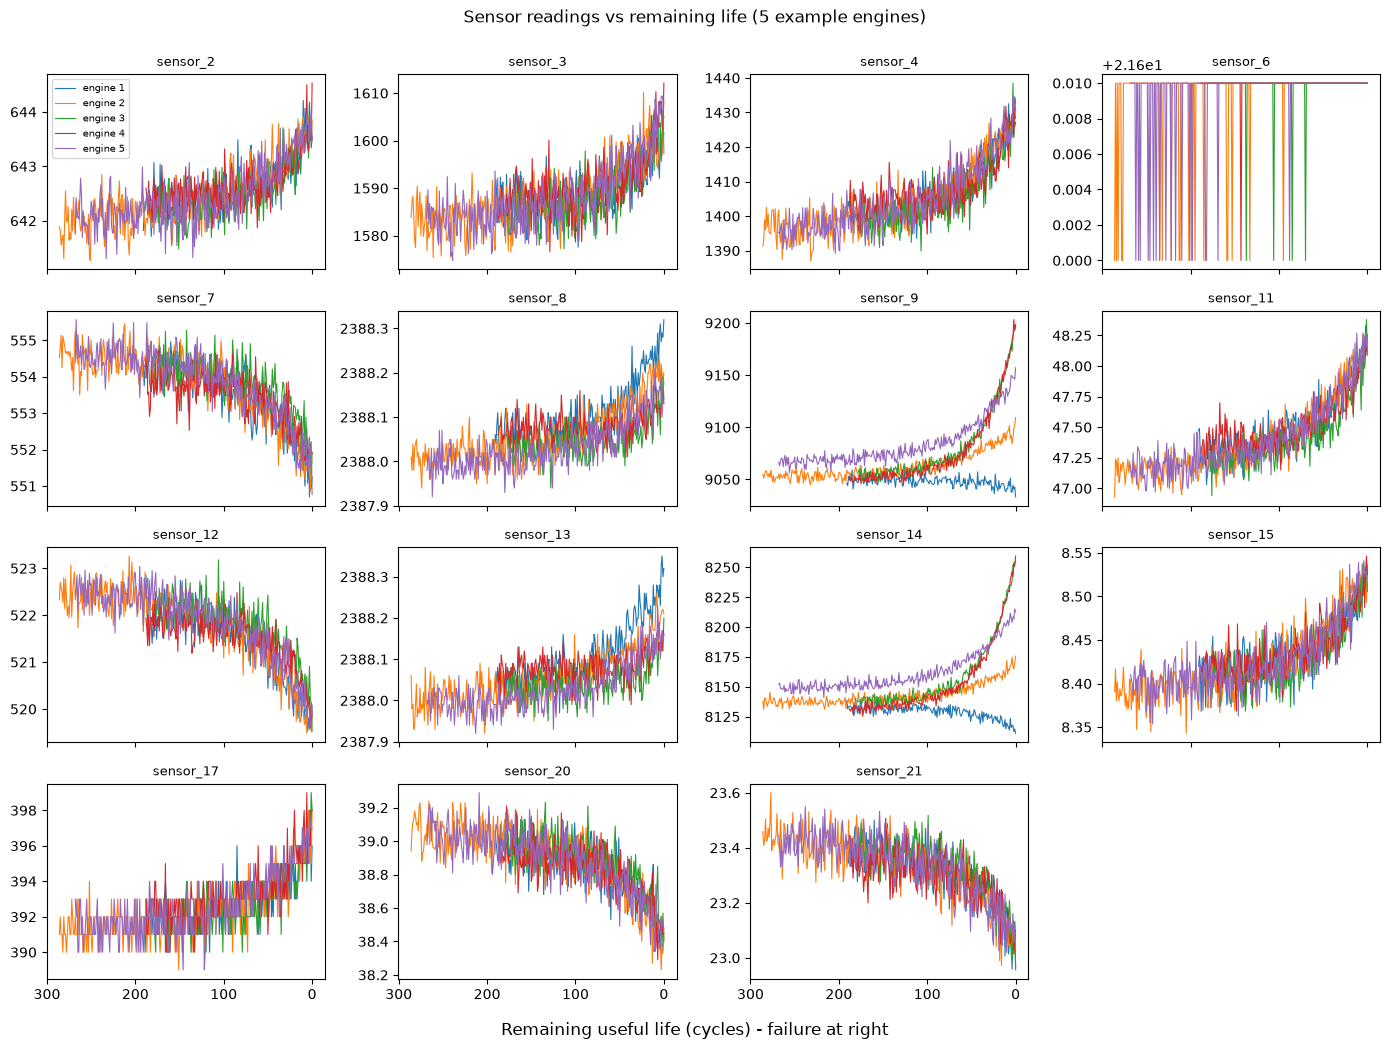

In [11]:
varying = [c for c in SENSOR_COLUMNS if c not in constant]
engines_to_plot = [1, 2, 3, 4, 5]

n_cols = 4
n_rows = int(np.ceil(len(varying) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 2.6 * n_rows), sharex=True)
for ax, sensor in zip(axes.ravel(), varying):
    for eng in engines_to_plot:
        d = train[train["engine"] == eng]
        ax.plot(d["RUL"], d[sensor], lw=0.8, label=f"engine {eng}")
    ax.set_title(sensor, fontsize=9)
    ax.invert_xaxis()  # time runs left to right: far from failure -> failure
for ax in axes.ravel()[len(varying):]:
    ax.set_visible(False)
axes.ravel()[0].legend(fontsize=7)
fig.supxlabel("Remaining useful life (cycles) - failure at right")
fig.suptitle("Sensor readings vs remaining life (5 example engines)", y=1.0)
fig.tight_layout()
plt.show()

**Your observation:** Which sensors show a clear trend toward failure? Which look like pure noise?
Do the trends go up or down? Are they similar across engines?

## 5. A quantitative check: correlation with RUL

In [12]:
# Spearman rank correlation captures monotonic trends, not just straight lines.
corr = train[varying].corrwith(train["RUL"], method="spearman")
corr_table = (
    corr.to_frame("spearman_vs_RUL")
    .assign(abs_corr=lambda d: d["spearman_vs_RUL"].abs())
    .sort_values("abs_corr", ascending=False)
    .round(3)
)
corr_table

,spearman_vs_RUL,abs_corr
sensor_11,-0.718,0.718
sensor_4,-0.702,0.702
sensor_12,0.693,0.693
sensor_7,0.679,0.679
sensor_15,-0.666,0.666
sensor_21,0.657,0.657
sensor_20,0.653,0.653
sensor_17,-0.629,0.629
sensor_2,-0.629,0.629
sensor_3,-0.606,0.606


**Your observation:** Do the strongest correlations match the sensors that trended in the plots?
Choose a rule for keeping sensors (for example an absolute-correlation threshold), state it,
and record the list of sensors you keep.

Caution: this ranks sensors using *all* training engines. When you evaluate models later,
be careful that any selection is done only on training folds, not on data the model is tested on.

## 6. Defining the RUL label: should it be capped?

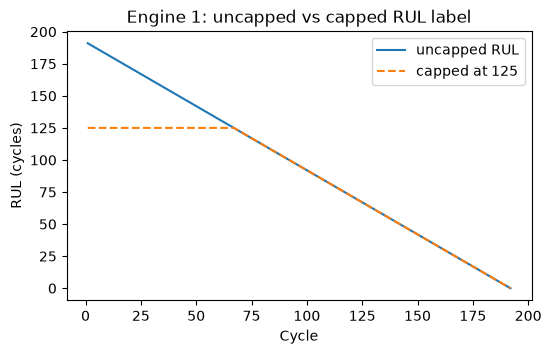

In [13]:
cap = 125  # a common starting value in the literature; treat as a tunable parameter
eng = train[train["engine"] == 1]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(eng["cycle"], eng["RUL"], label="uncapped RUL")
ax.plot(eng["cycle"], eng["RUL"].clip(upper=cap), "--", label=f"capped at {cap}")
ax.set_xlabel("Cycle")
ax.set_ylabel("RUL (cycles)")
ax.set_title("Engine 1: uncapped vs capped RUL label")
ax.legend()
plt.show()

**Your observation:** Early in life the sensors barely change (section 4), so a model cannot tell
an engine with 300 cycles left from one with 200 left. How does capping help with this?
What might capping cost you? Plan to test different caps as part of your sensitivity analysis.

## 7. Test set: how much history do we get?

In [14]:
test_len = test.groupby("engine")["cycle"].max()
print(test_len.describe().round(1))
print("Engines with fewer than 50 cycles:", int((test_len < 50).sum()))

count    100.0
mean     131.0
std       53.6
min       31.0
25%       88.8
50%      133.5
75%      164.2
max      303.0
Name: cycle, dtype: float64
Engines with fewer than 50 cycles: 7


**Your observation:** If your model looks at a fixed window of recent cycles, what should it do
for test engines shorter than the window? Write down your rule: it belongs in your
inputs/outputs section.

## Summary of decisions (fill in)

| Decision | Choice | Evidence |
| --- | --- | --- |
| Columns dropped |Sensors 1, 5, 6, 10, 16, 18 and 19 | They are constant throughout the cycles - they don't predict anything. For settings 1 and 2, the standard deviation between values is low, and the weak correlation with the kept sensors.|
| Sensors kept | Sensors 4,7,11,12,15 and 21| These senors are non-constant, as they measure parmeters that were close to the point of failure.|
| RUL cap | The cap is to be implemented. |The cap is to be implemented as it is realistic of the actual model conditions - it can't tell if there are 300 cycles left or 200, as the sensor values are flat. It wastes effort and error on a distinction that the model can't support. |
| Short-series rule |Baseline on single rows, then windows of W = 30, and test longer windows later. | The smallest data set is 31 cycles, and there are multiple other data sets that are below 50 cycles. |